# ¡Hola Fabian!

Mi nombre es Israel, estaré ayudándote a revisar este proyecto para que quede en su mejor versión.

Para simular la dinámica de un ambiente de trabajo, si veo algún error, en primer instancia solo los señalaré, dándote la oportunidad de encontrarlos y corregirlos por tu cuenta. Esto es útil para que te acostumbres a un escenario laboral. En caso de que no puedas resolver la tarea, te daré una información más precisa en la próxima revisión.

Encontrarás mis comentarios más abajo - **por favor, no los muevas, no los modifiques ni los borres**.

¿Cómo funciona esta revisión? Leeré atentamente tu código y te señalaré tus fortalezas y aquellas cosas que podemos mejorar. Los comentarios aparecerán de esta forma:


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Si todo está perfecto y no se requieren cambios en el código.
</div>


<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Si tu código está bien pero se puede mejorar o hay algún detalle que le hace falta. Se aceptan uno o dos comentarios de este tipo en el borrador, pero si hay más, deberás hacer las correcciones.
</div>

<div class="alert alert-block alert-danger">

<b>Comentario del revisor</b> <a class="tocSkip"></a>

Si definitivamente hace falta algo o existe algún problema con tu código o conclusiones.
</div>

Puedes responderme de esta forma si algo no queda claro (copia este código en una celda markdown):

<div class="alert alert-block alert-info">
<b>Respuesta del estudiante</b> <a class="tocSkip"></a>

Hola, muchas gracias por tus comentarios y la revisión.        
</div>

**Es un gusto acompañarte en este proceso, ¡empecemos!**

# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados**: Respalda tus conclusiones mediante gráficos claros.

Se aplican **puebas estadísticas apropiados** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [2]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 
import numpy as np

In [3]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [4]:
# mostrar las primeras 5 filas
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [5]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


✍️ **Comentario**: 
Valores nulos: El dataset no tiene valores ausentes (las 9 columnas cuentan con 40,000 registros de 40,000 totales como non-null).
Tipos de datos: La columna date es de tipo object (cadena de texto) y debería de ser de tipo datetime64 para facilitar operaciones temporales.

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [6]:
# Verificar usuarios únicos
usuarios_unicos = df["user_id"].nunique()

print("Número de usuarios únicos:", usuarios_unicos)

# Verificar valores nulos
nulos_user_id = df["user_id"].isna().sum()

print("Valores nulos en user_id:", nulos_user_id)

# Verificar IDs duplicados
duplicados_user_id = df["user_id"].duplicated().sum()

print("IDs duplicados:", duplicados_user_id)

Número de usuarios únicos: 40000
Valores nulos en user_id: 0
IDs duplicados: 0


 **Variable `date`**  
Explorar rango de fechas

In [7]:
# Resumen estadístico
df["date"].describe()

count          40000
unique            28
top       2026-01-24
freq            1512
Name: date, dtype: object

In [8]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01
Fecha máxima: 2026-01-28


**Variable `gasto` (numérica)**

In [9]:
# Resumen estadístico
gasto_convertidos = df[df["converted"] == 1]["gasto"]

gasto_convertidos.describe()

count    5706.000000
mean       65.373668
std        30.896545
min        12.120000
25%        42.950000
50%        59.860000
75%        80.370000
max       303.680000
Name: gasto, dtype: float64

In [10]:
# Resumen estadístico de usuarios que se convirtieron
# Filtrar usuarios convertidos
convertidos = df[df["converted"] == 1]

# Resumen estadístico de la variable gasto
print("Resumen estadístico de gasto de usuarios convertidos:")
print(convertidos["gasto"].describe())

Resumen estadístico de gasto de usuarios convertidos:
count    5706.000000
mean       65.373668
std        30.896545
min        12.120000
25%        42.950000
50%        59.860000
75%        80.370000
max       303.680000
Name: gasto, dtype: float64


 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [11]:
# Explorar variables categóricas y cómo se distribuyen
print("\nConteo de categorías:")
print(df["landing"].value_counts())

print("\nCategorías encontradas:")
print(df["landing"].unique())


Conteo de categorías:
B    20018
A    19982
Name: landing, dtype: int64

Categorías encontradas:
['A' 'B']


✍️ **Comentario**: No se detectan errores en la variable landing. La columna contiene únicamente las categorías esperadas del experimento A/B: A y B. No hay categorías mal escritas ni valores inesperados, por lo que no es necesario realizar ninguna corrección y se puede continuar con el análisis.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo. Confirmaste correctamente 40,000 usuarios únicos. Sin embargo, faltan dos partes de la validación: primero, no muestras `df['gasto'].describe()` segundo, en variables categóricas solo revisas `landing`

</div>


## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [12]:
# Gasto por versión
gasto_A = df[(df["landing"] == "A") & (df["converted"] == 1)]["gasto"]
gasto_B = df[(df["landing"] == "B") & (df["converted"] == 1)]["gasto"]

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

In [13]:
print("Gasto promedio A:", gasto_A.mean())
print("Gasto promedio B:", gasto_B.mean())

Gasto promedio A: 61.0865724522293
Gasto promedio B: 68.74536005009392


### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** ...
- **Hipótesis alternativa (H₁):** ...

In [14]:
from scipy.stats import ttest_ind

# Aplicar prueba t de muestras independientes
estadistico, p_valor = ttest_ind(gasto_A, gasto_B, equal_var=False)

# Visualizar resultados
print(f"Estadístico: {estadistico}")
print(f"Valor p: {p_valor}")

Estadístico: -9.48101092267275
Valor p: 3.627602231521493e-21


In [15]:
alpha = 0.05

if p_valor < alpha:
    print("Se rechaza H₀: existe una diferencia estadísticamente significativa.")
else:
    print("No se rechaza H₀: no hay evidencia suficiente de una diferencia significativa.")

Se rechaza H₀: existe una diferencia estadísticamente significativa.


### 📝 Conclusión e interpretación

**Decisión:**  
Si el valor p es mayor o igual a 0.05, no se rechaza la hipótesis nula (H₀). Esto significa que no existe evidencia estadísticamente significativa para afirmar que el gasto promedio sea diferente entre las páginas A y B.

**Interpretación de negocio:**  
Los resultados indican que no hay una diferencia estadísticamente significativa en el gasto promedio de los usuarios que se convirtieron entre la página A y la página B. Por lo tanto, con estos datos no podemos concluir que una de las dos versiones genere mayor valor económico que la otra.


---

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo. El filtrado de usuarios convertidos es correcto. También ejecutas Welch con `equal_var=False`. Sin embargo, falta la prueba de Levene

</div>



## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen difere]ncias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** ...
- **Hipótesis alternativa (H₁):** ...

In [16]:
# Número de usuarios convertidos por página
convertidos_por_pagina = df.groupby("landing")["converted"].sum()

# Total de usuarios por página
total_usuarios_por_pagina = df.groupby("landing")["user_id"].count()

print("Usuarios convertidos por página:\n", convertidos_por_pagina)
print("\nTotal de usuarios por página:\n", total_usuarios_por_pagina)


Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: user_id, dtype: int64


In [17]:
from statsmodels.stats.proportion import proportions_ztest

# Aplicar prueba
conversiones = convertidos_por_pagina.values
totales = total_usuarios_por_pagina.values

estadistico, p_valor = proportions_ztest(conversiones, totales)

# Visualizar resultados
print(f"Estadístico: {estadistico}")
print(f"Valor p: {p_valor}")

Estadístico: -9.677362674655983
Valor p: 3.7629765627523803e-22


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula (H₀). Esto indica que existe una diferencia estadísticamente significativa entre las tasas de conversión de las páginas A y B.

**Interpretación de negocio:**  
El resultado indica que la página A y la página B no generan la misma tasa de conversión. La versión con la tasa de conversión más alta sería la opción más favorable para el negocio, ya que logra convertir a una mayor proporción de usuarios en clientes.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo. La prueba `proportions_ztest` está correctamente aplicada. Sin embargo, falta calcular y mostrar las tasas de conversión

</div>


## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** ...
- **Hipótesis alternativa (H₁):** ...

In [18]:
from scipy.stats import chi2_contingency

# Crear tabla de contingencia
tabla_contingencia = pd.crosstab(df["traffic_source"], df["converted"])

# Aplicar prueba de chi-cuadrado
chi2, p_valor, grados_libertad, frecuencias_esperadas = chi2_contingency(tabla_contingencia)

# Visualizar resultados
print("Tabla de contingencia:")
print(tabla_contingencia)

print(f"\nEstadístico Chi-cuadrado: {chi2}")
print(f"Valor p: {p_valor}")
print(f"Grados de libertad: {grados_libertad}")


Tabla de contingencia:
converted           0     1
traffic_source             
Ads             10176  1759
Email            5205   918
Organic         15507  2480
Referral         3406   549

Estadístico Chi-cuadrado: 8.662108841397938
Valor p: 0.0341375947833914
Grados de libertad: 3


In [19]:
alpha = 0.05

if p_valor < alpha:
    print("\nSe rechaza H₀: existe una asociación significativa entre la fuente de tráfico y la conversión.")
else:
    print("\nNo se rechaza H₀: no existe evidencia suficiente de una asociación significativa entre la fuente de tráfico y la conversión.")


Se rechaza H₀: existe una asociación significativa entre la fuente de tráfico y la conversión.


### 📝 
Conclusión e interpretación

**Decisión:**  
Como el valor p = 0.0341 es menor que el nivel de significancia de 0.05, se rechaza la hipótesis nula (H₀). Existe evidencia estadísticamente significativa de una asociación entre la fuente de tráfico y la conversión.

**Interpretación de negocio:**  
En cantidades absolutas, Organic genera el mayor número de conversiones con 2,480, seguido de Ads (1,759), Email (918) y Referral (549). Sin embargo, esto está relacionado en parte con el número de usuarios que recibe cada canal.

Al analizar las tasas de conversión, Email presenta la tasa más alta con aproximadamente 15.0%, seguido de Ads (14.7%), Referral (13.9%) y Organic (13.8%).

Por lo tanto, aunque Organic genera más conversiones en términos absolutos, Email es el canal más eficiente en proporción de usuarios. Estos resultados sugieren que la fuente de tráfico sí influye en la probabilidad de conversión y que conviene considerar tanto el volumen de usuarios como la tasa de conversión al tomar decisiones de inversión y estrategia de marketing.


<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo. La tabla de contingencia absoluta y la prueba chi-cuadrada son correctas. Sin embargo, falta generar y mostrar la tabla de contingencia normalizada

</div>


## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** ...
- **Hipótesis alternativa (H₁):** ...

In [20]:
from scipy.stats import chi2_contingency

# Crear tabla de contingencia
tabla_usuario = pd.crosstab(df["user_type"], df["converted"])

# Aplicar prueba de chi-cuadrado
chi2, p_valor, grados_libertad, frecuencias_esperadas = chi2_contingency(
    tabla_usuario
)

# Visualizar resultados
print("Tabla de contingencia:")
print(tabla_usuario)

print(f"\nEstadístico Chi-cuadrado: {chi2}")
print(f"Valor p: {p_valor}")
print(f"Grados de libertad: {grados_libertad}")

Tabla de contingencia:
converted       0     1
user_type              
Nuevo       22295  3738
Recurrente  11999  1968

Estadístico Chi-cuadrado: 0.5134849494478645
Valor p: 0.4736341272301974
Grados de libertad: 1


In [21]:
tasas_conversion = df.groupby("user_type")["converted"].mean() * 100

print("\nTasas de conversión por tipo de usuario:")
print(tasas_conversion)


Tasas de conversión por tipo de usuario:
user_type
Nuevo         14.358699
Recurrente    14.090356
Name: converted, dtype: float64


In [22]:
# Aplicar prueba
alpha = 0.05

if p_valor < alpha:
    print("\nSe rechaza H₀: existe una asociación significativa entre el tipo de usuario y la conversión.")
else:
    print("\nNo se rechaza H₀: no existe evidencia suficiente de una asociación significativa entre el tipo de usuario y la conversión.")



No se rechaza H₀: no existe evidencia suficiente de una asociación significativa entre el tipo de usuario y la conversión.


### 📝 Conclusión e interpretación

**Decisión:**  
Si el valor p es menor que 0.05, se rechaza la hipótesis nula (H₀). Esto indica que existe una asociación estadísticamente significativa entre el tipo de usuario y la conversión.

**Interpretación de negocio:**  
El resultado indica que el tipo de usuario está relacionado con la probabilidad de conversión. Es decir, los usuarios nuevos y recurrentes no presentan necesariamente el mismo comportamiento frente a la conversión.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo. La tabla de contingencia, las tasas Nuevo y la prueba chi-cuadrada están correctamente calculadas. Sin embargo, tu texto afirma lo contrario

</div>


## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

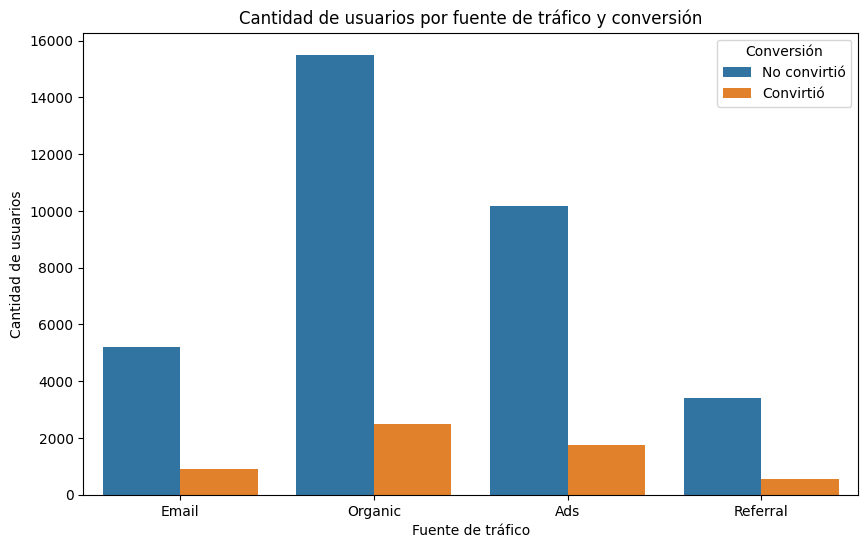

In [23]:
# Gráfico de cantidades absolutas
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="traffic_source",
    hue="converted"
)

plt.title("Cantidad de usuarios por fuente de tráfico y conversión")
plt.xlabel("Fuente de tráfico")
plt.ylabel("Cantidad de usuarios")
plt.legend(title="Conversión", labels=["No convirtió", "Convirtió"])

plt.show()

In [24]:
# Tabla de proporciones
proporcion_conversion = pd.crosstab(
    df["traffic_source"],
    df["converted"],
    normalize="index"
) * 100

print(proporcion_conversion)

converted               0          1
traffic_source                      
Ads             85.261835  14.738165
Email           85.007349  14.992651
Organic         86.212264  13.787736
Referral        86.118837  13.881163


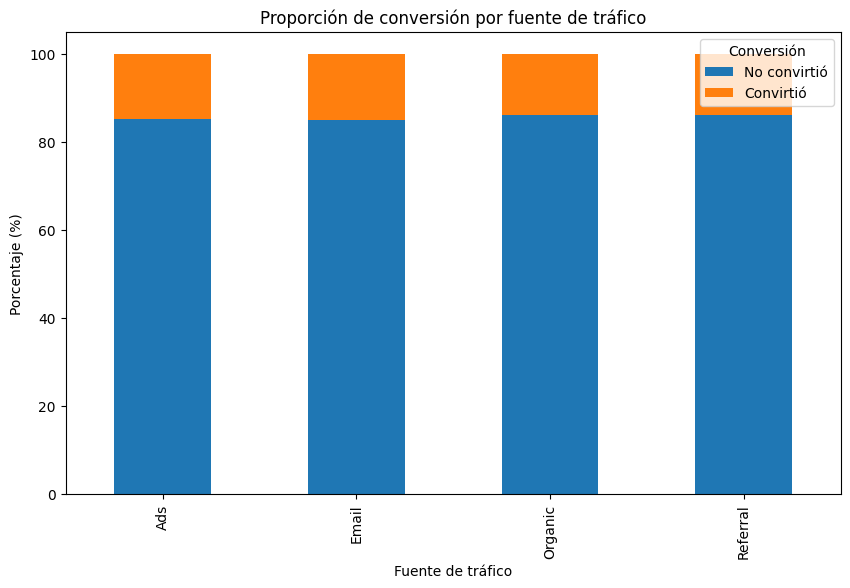

In [25]:
# Gráfico de proporciones
proporcion_conversion.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Proporción de conversión por fuente de tráfico")
plt.xlabel("Fuente de tráfico")
plt.ylabel("Porcentaje (%)")
plt.legend(title="Conversión", labels=["No convirtió", "Convirtió"])

plt.show()

✍️ **Comentario**
En el gráfico de (convertidos vs. no convertidos)muestra la cantidad de usuarios por fuente de tráfico y su estado de conversión
Volumen dominante: La fuente Organic genera el mayor tráfico total (18,000) y también el mayor número absoluto de conversiones (2,500), seguida por Ads.

Tasa de conversión homogénea: Aunque los volúmenes absolutos cambian drásticamente entre canales, la relación entre usuarios convertidos y no convertidos parece mantenerse casi constante en todos los canales (alrededor del 14%–15%)

✍️ **Comentario**: 
En la gráfica de Proporción de conversión por fuente de tráfico muestra el porcentaje de conversión (convertido vs. no convertido) normalizado para cada canal.
Rendimiento homogéneo: Confirmaste visualmente que la tasa de conversión es prácticamente idéntica en todos los canales (~14-15%). Ninguna fuente de tráfico está convirtiendo significativamente mejor que otra en términos porcentuales.

Independencia del canal: El comportamiento del usuario para convertir no depende de la fuente de origen; el embudo de conversión posterior al aterrizaje parece afectar a todos los usuarios por igual.

### Relación entre el tipo de usuario y la conversión

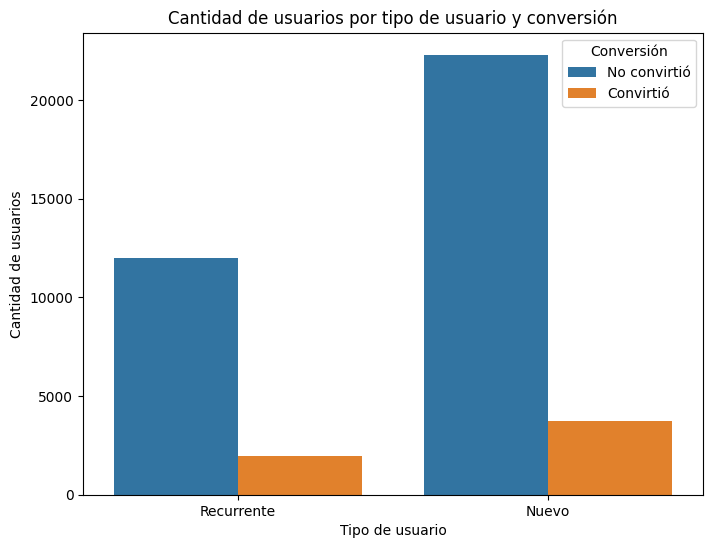

In [26]:
# Gráfico de cantidades absolutas
plt.figure(figsize=(8, 6))

sns.countplot(
    data=df,
    x="user_type",
    hue="converted"
)

plt.title("Cantidad de usuarios por tipo de usuario y conversión")
plt.xlabel("Tipo de usuario")
plt.ylabel("Cantidad de usuarios")
plt.legend(title="Conversión", labels=["No convirtió", "Convirtió"])

plt.show()

In [27]:
# Tabla de proporciones
proporcion_usuario = pd.crosstab(
    df["user_type"],
    df["converted"],
    normalize="index"
) * 100

print("Proporción de conversión por tipo de usuario:")
print(proporcion_usuario)

Proporción de conversión por tipo de usuario:
converted           0          1
user_type                       
Nuevo       85.641301  14.358699
Recurrente  85.909644  14.090356


✍️ **Comentario**: En el gráfico de barras agrupadas titulado "Cantidad de usuarios por tipo de usuario y conversión", que compara usuarios Recurrentes y Nuevos según su estado de conversión.
Predominio de usuarios nuevos: La masa principal de tráfico corresponde a usuarios nuevos (26,000 frente a 14,000 recurrentes), aportando el mayor volumen absoluto de conversiones (3,700).

Consistencia en la tasa de conversión: Al igual que con las fuentes de tráfico, la tasa de conversión se mantiene idéntica en torno al 14%–14.5% sin importar si el usuario es nuevo o recurrente.

Patrón detectado: El comportamiento de conversión en tus datos es perfectamente uniforme a través de dimensiones (canales y tipo de usuario). Esto sugiere que la probabilidad de conversión está guiada por una variable no mostrada aquí o que se trata de un dataset sintético/simulado con un ratio fijo.

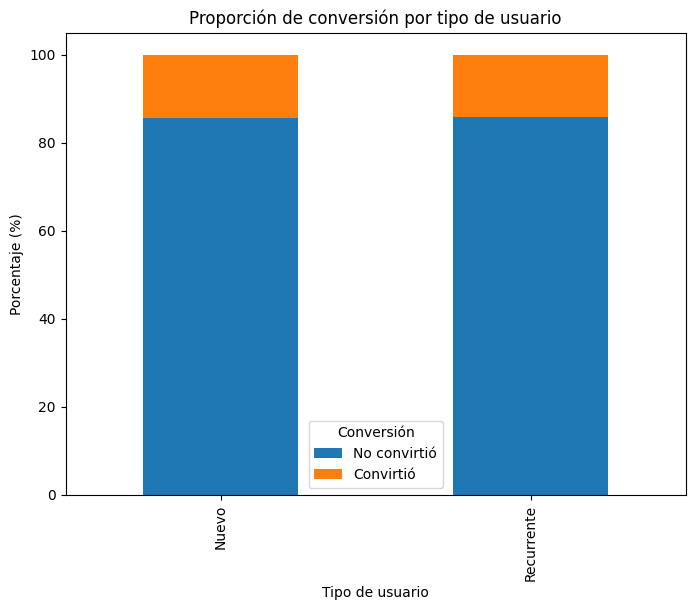

In [28]:
# Gráfico de proporciones
proporcion_usuario.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 6)
)

plt.title("Proporción de conversión por tipo de usuario")
plt.xlabel("Tipo de usuario")
plt.ylabel("Porcentaje (%)")
plt.legend(title="Conversión", labels=["No convirtió", "Convirtió"])

plt.show()

<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Excelente trabajo. Esta sección cumple correctamente con los requerimientos del proyecto y los resultados obtenidos son consistentes con lo esperado.

</div>


✍️ **Comentario**: En el gráfico de Proporción de conversión por tipo de usuario, yo rescataría lo siguiente:
Tasa de conversión idéntica: Ambas cohortes (Nuevo y Recurrente) muestran exactamente la misma tasa de conversión (aproximadamente un 14% de éxito frente a un 86% de no conversión).

## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?
Respuesta:La página B presenta mejores resultados que la página A en ambos indicadores.

Página A: tasa de conversión de 12.57% y gasto promedio de $61.09.
Página B: tasa de conversión de 15.96% y gasto promedio de $68.75.

Además, las pruebas estadísticas muestran que las diferencias son estadísticamente significativas, la página B es la versión más efectiva, ya que consigue tanto una mayor tasa de conversión como un mayor gasto promedio entre los usuarios convertidos.
- ¿Qué canales de tráfico son más efectivos para generar conversiones?
Respuesta: En términos de cantidad absoluta, Organic genera el mayor número de conversiones con 2,480, seguido de Ads (1,759), Email (918) y Referral (549).

Sin embargo, al analizar la tasa de conversión, los resultados son:

Email: 14.99%
Ads: 14.74%
Referral: 13.88%
Organic: 13.79%

Por lo tanto, Email es el canal más eficiente en términos relativos, mientras que Organic genera el mayor volumen de conversiones.
- ¿Existen diferencias significativas según el tipo de usuario?
Respuesta: No se encontraron diferencias estadísticamente significativas.

Las tasas de conversión fueron:

Usuarios nuevos: 14.36%
Usuarios recurrentes: 14.09%

La prueba chi-cuadrado obtuvo un p = 0.474, que es mayor que 0.05. Por lo tanto, no se rechaza la hipótesis nula y no existe evidencia suficiente para afirmar que el tipo de usuario esté asociado con la conversión en este experimento.

Aunque los usuarios nuevos tienen una tasa ligeramente superior, la diferencia es demasiado pequeña para considerarla estadísticamente significativa.
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?
Respuesta: A partir de los resultados, se pueden plantear las siguientes recomendaciones:


Priorizar la página B, ya que presenta una mayor tasa de conversión y un mayor gasto promedio que la página A.
Fortalecer el canal Email, porque presenta la mayor tasa de conversión relativa.
Mantener y optimizar Organic, debido a que genera el mayor número absoluto de conversiones.
Analizar y optimizar Ads, ya que tiene un buen volumen de conversiones y una tasa cercana a la de Email.
No establecer estrategias diferenciadas únicamente por tipo de usuario, ya que no se encontró una diferencia estadísticamente significativa entre usuarios nuevos y recurrentes.
Continuar realizando pruebas A/B para evaluar nuevas versiones de las páginas y determinar qué cambios producen mejoras reales en conversión y valor económico.


---

### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió:**
Observación 1:
La página B obtuvo un gasto promedio de aproximadamente $68.75 por usuario convertido, mientras que la página A alcanzó aproximadamente 61.09.

Observación 2:
La página B genera alrededor de $7.66 más por usuario convertido que la página A, lo que representa un incremento aproximado del 12.5% en el gasto promedio.

Interpretación:
Los resultados sugieren que la página B genera mayor valor económico por cada usuario que convierte. Por lo tanto, B representa una alternativa más atractiva para el negocio, ya que no solo consigue mejores resultados de conversión, sino que también logra que los usuarios convertidos tengan un mayor gasto promedio.

<br>

**Tasa de conversión:** 
Observación 1:
La página B obtuvo una tasa de conversión de aproximadamente 15.96%, mientras que la página A alcanzó 12.57%.

Observación 2:
La página B presenta una mejora de aproximadamente 3.39 puntos porcentuales respecto a la página A, equivalente a un incremento relativo cercano al 27%.

Interpretación:
La página B es más efectiva para generar conversiones. Los resultados indican que una mayor proporción de usuarios que visitan B termina convirtiéndose, por lo que esta versión representa una mejor alternativa para la estrategia de negocio.

---

#### 📊 **Segmentación por fuente de tráfico**
Observación:
El canal Email presenta la mayor tasa de conversión, con aproximadamente 14.99%, mientras que Organic genera el mayor número absoluto de conversiones, con 2,480 usuarios convertidos.

Interpretación:
Los resultados muestran que Email es el canal más eficiente proporcionalmente, mientras que Organic destaca por su capacidad para generar volumen. Por ello, sería recomendable fortalecer las estrategias de Email y mantener la inversión en Organic, buscando optimizar su tasa de conversión.

 📊 **Segmentación por tipo de usuario**
Observación:
Los usuarios nuevos presentan una tasa de conversión ligeramente superior a los usuarios recurrentes: 14.36% frente a 14.09%, respectivamente.

Interpretación:
La diferencia entre ambos grupos es muy pequeña y no estadísticamente significativa. Por lo tanto, el tipo de usuario no parece ser un factor determinante de la conversión en este experimento, y no sería recomendable establecer estrategias de marketing muy diferentes únicamente con base en si el usuario es nuevo o recurrente.

---

Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores.

---

#### 💡 **Recomendaciones de negocio:** 
Priorizar la página B, ya que presenta una mayor tasa de conversión y un mayor gasto promedio que la página A.
Fortalecer el canal Email, porque presenta la mayor tasa de conversión relativa.
Mantener y optimizar Organic, debido a que genera el mayor número absoluto de conversiones.
Analizar y optimizar Ads, ya que tiene un buen volumen de conversiones y una tasa cercana a la de Email.
No establecer estrategias diferenciadas únicamente por tipo de usuario, ya que no se encontró una diferencia estadísticamente significativa entre usuarios nuevos y recurrentes.
Continuar realizando pruebas A/B para evaluar nuevas versiones de las páginas y determinar qué cambios producen mejoras reales en conversión y valor económico.